<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Custom embedddings con Gensim



### Objetivo
Crear embeddings de palabras propios con **Word2Vec (Gensim)** a partir de un corpus distinto al visto en clase, y estudiarlos:

1. Probar términos de interés y explicar sus similitudes en el espacio de embeddings.
2. Plantear y probar tests de analogías.
3. Graficar los embeddings (reducción a 2D/3D) e interpretar los grupos que se forman.
4. Sacar conclusiones, justificando las decisiones de hiperparámetros.

**Corpus elegido:** cuatro libros de Sherlock Holmes (Arthur Conan Doyle) de Project Gutenberg. Es texto narrativo largo, con personajes, lugares y acciones recurrentes, lo que debería producir grupos interpretables.

In [1]:
import os
import re
import urllib.request
import multiprocessing

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import Word2Vec

### Datos
Usamos cuatro obras de Sherlock Holmes en inglés, de dominio público (Project Gutenberg):

| ID | Obra |
|---|---|
| 1661 | *The Adventures of Sherlock Holmes* |
| 2852 | *The Hound of the Baskervilles* |
| 244 | *A Study in Scarlet* |
| 2097 | *The Sign of the Four* |

Se descargan una sola vez a la carpeta `gutenberg/`.

In [2]:
GUTENBERG_DIR = "gutenberg"
LIBROS = {
    1661: "adventures_of_sherlock_holmes",
    2852: "hound_of_the_baskervilles",
    244: "study_in_scarlet",
    2097: "sign_of_the_four",
}

os.makedirs(GUTENBERG_DIR, exist_ok=True)
for libro_id, nombre in LIBROS.items():
    ruta = os.path.join(GUTENBERG_DIR, f"{nombre}.txt")
    if os.path.exists(ruta):
        print(f"{nombre}: ya descargado")
    else:
        urllib.request.urlretrieve(f"https://www.gutenberg.org/cache/epub/{libro_id}/pg{libro_id}.txt", ruta)
        print(f"{nombre}: descargado")

adventures_of_sherlock_holmes: ya descargado
hound_of_the_baskervilles: ya descargado
study_in_scarlet: ya descargado
sign_of_the_four: ya descargado


In [3]:
# Libros disponibles y su tamaño
for archivo in sorted(os.listdir(GUTENBERG_DIR)):
    print(f"{archivo}: {os.path.getsize(os.path.join(GUTENBERG_DIR, archivo)) / 1024:.0f} KB")

adventures_of_sherlock_holmes.txt: 593 KB
hound_of_the_baskervilles.txt: 379 KB
sign_of_the_four.txt: 255 KB
study_in_scarlet.txt: 262 KB


In [4]:
def extraer_texto(ruta):
    """Devuelve solo el texto de la obra, sin el encabezado ni la licencia de Gutenberg."""
    with open(ruta, encoding="utf-8") as f:
        crudo = f.read()
    inicio = re.search(r"\*\*\* START OF.*?\*\*\*", crudo).end()
    fin = re.search(r"\*\*\* END OF", crudo).start()
    return crudo[inicio:fin]

texto = " ".join(extraer_texto(os.path.join(GUTENBERG_DIR, f"{nombre}.txt")) for nombre in LIBROS.values())

# Gutenberg corta las líneas a ~70 caracteres: una línea NO es una oración.
# Unimos todo en un único texto y normalizamos comillas tipográficas, guiones largos e itálicas (_texto_).
texto = " ".join(texto.split())
for original, reemplazo in {"’": "'", "‘": "'", "“": " ", "”": " ", "—": " ", "_": " "}.items():
    texto = texto.replace(original, reemplazo)

# Segmentamos en oraciones: cortamos después de . ! o ? seguidos de espacio
oraciones = re.split(r"(?<=[.!?])\s+", texto)
oraciones[:5]

['The Adventures of Sherlock Holmes by Arthur Conan Doyle Contents I.',
 'A Scandal in Bohemia II.',
 'The Red-Headed League III.',
 'A Case of Identity IV.',
 'The Boscombe Valley Mystery V.']

In [5]:
print("Cantidad de oraciones (documentos):", len(oraciones))

Cantidad de oraciones (documentos): 16841


### 1 - Preprocesamiento
Word2Vec aprende de **ventanas de contexto** dentro de cada secuencia de tokens. Por eso la unidad de entrenamiento es la **oración**: la ventana no debe cruzar de una oración a otra sin relación.

Para tokenizar usamos `text_to_word_sequence` (Keras), que pasa a minúsculas, separa por espacios y elimina la puntuación ASCII. Además quitamos los apóstrofes que quedan al inicio o al final de una palabra (citas como `'where`, o posesivos como `holmes'`), y descartamos las "oraciones" de un solo token (títulos, números de capítulo), que no aportan contexto.

In [6]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

sentence_tokens = []
for oracion in oraciones:
    tokens = [t.strip("'") for t in text_to_word_sequence(oracion)]
    tokens = [t for t in tokens if t]
    if len(tokens) > 1:
        sentence_tokens.append(tokens)

I0000 00:00:1794080272.165989   44865 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794080272.202783   44865 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794080272.947218   44865 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [7]:
# Demos un vistazo
print("Oraciones:", len(sentence_tokens))
print("Tokens totales:", sum(len(t) for t in sentence_tokens))
print("Palabras distintas:", len({w for t in sentence_tokens for w in t}))
sentence_tokens[10:13]

Oraciones: 16262
Tokens totales: 251952
Palabras distintas: 13037


[['the', 'adventure', 'of', 'the', 'noble', 'bachelor', 'xi'],
 ['the', 'adventure', 'of', 'the', 'beryl', 'coronet', 'xii'],
 ['the', 'adventure', 'of', 'the', 'copper', 'beeches', 'i']]

### 2 - Crear los vectores (word2vec)

**Idea.** Es la misma hipótesis distribucional del Desafío 1 ("una palabra se define por su contexto"), pero en lugar de contar en qué documentos aparece cada palabra, Word2Vec entrena una red neuronal de una capa oculta para **predecir contexto**. Los pesos de esa capa son los embeddings: vectores **densos** de pocas dimensiones, en vez de vectores esparsos de miles de dimensiones.

- **Skip-gram (`sg=1`)**: dada la palabra central, predice las vecinas. Suele ir mejor con palabras poco frecuentes.
- **CBOW (`sg=0`)**: dado el promedio del contexto, predice la palabra central. Es más rápido y suaviza el ruido de las palabras frecuentes.
- **Negative sampling (`negative`)**: en vez de un softmax sobre todo el vocabulario, por cada par real (palabra, contexto) se muestrean *n* palabras "falsas" y se entrena un clasificador binario.

**Hiperparámetros del modelo base y por qué:**

| Parámetro | Valor | Justificación |
|---|---|---|
| `min_count` | 5 | Una palabra con menos de 5 apariciones no tiene suficientes contextos para un vector confiable (el mismo problema de df=1 del Desafío 1). |
| `window` | 5 | Contexto de ±5 palabras: captura relaciones semánticas además de sintácticas. Se compara con 2 más abajo. |
| `vector_size` | 100 | Con ~250 mil tokens, 300 dimensiones (el valor de clase) es mucha capacidad para pocos datos. Se compara más abajo. |
| `negative` | 20 | Como se vio en clase, para corpus pequeños el muestreo negativo debe ser mayor (además actúa como regularización). Es el valor usado en el ejemplo de clase. |
| `workers` | núcleos de la CPU | Gensim entrena en CPU con varios hilos (`multiprocessing.cpu_count()`). |
| `seed` | 0 | Fija el azar del algoritmo (inicialización y muestras negativas). |

**Reproducibilidad.** Con varios hilos el resultado cambia levemente en cada ejecución, aunque haya `seed`: cada hilo actualiza los vectores compartidos en un orden que decide el sistema operativo. Para obtener resultados idénticos entre ejecuciones hay que usar `seed=0` **y** `workers=1` (más lento). Se puede activar con `REPRODUCIBLE = True` en la celda siguiente.

Encapsulamos la creación en una función para reutilizarla en los experimentos.

In [8]:
from gensim.models.callbacks import CallbackAny2Vec
# Durante el entrenamiento gensim por defecto no informa el "loss" en cada época
# Sobrecargamos el callback para poder tener esta información
class callback(CallbackAny2Vec):
    """
    Callback to print loss after each epoch
    """
    def __init__(self):
        self.epoch = 0
        self.losses = []

    def on_epoch_end(self, model):
        # get_latest_training_loss() es acumulativo: restamos el de la época anterior
        loss = model.get_latest_training_loss()
        epoch_loss = loss if self.epoch == 0 else loss - self.loss_previous_step
        print('Loss after epoch {}: {}'.format(self.epoch, epoch_loss))
        self.losses.append(epoch_loss)
        self.epoch += 1
        self.loss_previous_step = loss

In [9]:
# Opcional: True => workers=1 y seed=0, resultados idénticos en cada ejecución (entrena más lento)
REPRODUCIBLE = False

def crear_modelo(sg=1, window=5, vector_size=100):
    return Word2Vec(min_count=5,                 # frecuencia mínima de palabra para incluirla en el vocabulario
                    window=window,               # cant de palabras antes y desp de la predicha
                    vector_size=vector_size,     # dimensionalidad de los vectores
                    negative=20,                 # cantidad de negative samples (mayor en corpus pequeños)
                    workers=1 if REPRODUCIBLE else multiprocessing.cpu_count(),
                    seed=0,
                    sg=sg)                       # modelo 0:CBOW  1:skipgram

# Modelo base: Skipgram, como en clase
w2v_model = crear_modelo(sg=1)

In [10]:
# Obtener el vocabulario con los tokens
w2v_model.build_vocab(sentence_tokens)

In [11]:
# Cantidad de filas/docs encontradas en el corpus
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)

Cantidad de docs en el corpus: 16262


In [12]:
# Cantidad de words encontradas en el corpus
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Cantidad de words distintas en el corpus: 3830


### 3 - Entrenar embeddings
Entrenamos 30 épocas: el corpus es chico, así que necesita varias pasadas para que los vectores se estabilicen. El *loss* de Gensim sirve para ver la **tendencia** (que el entrenamiento converge), no como medida de calidad de los embeddings.

Loss after epoch 0: 256533.09375


Loss after epoch 1: 237551.53125


Loss after epoch 2: 220220.5625


Loss after epoch 3: 226785.4375


Loss after epoch 4: 212677.125


Loss after epoch 5: 209405.125


... (20 outputs left out)

Loss after epoch 26: 159786.0


Loss after epoch 27: 161985.0


Loss after epoch 28: 162972.0


Loss after epoch 29: 158874.0


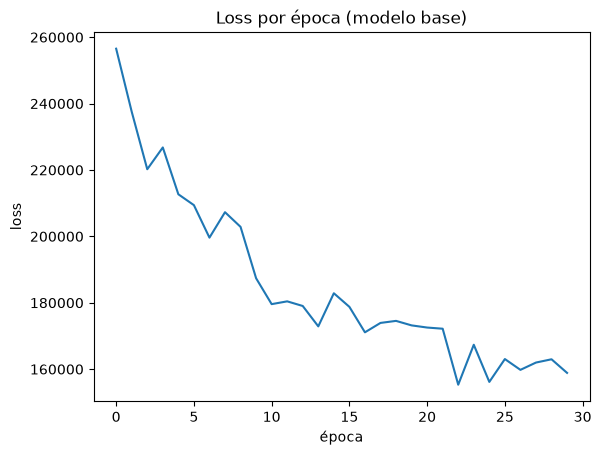

In [13]:
EPOCHS = 30

# Entrenamos el modelo generador de vectores
# Utilizamos nuestro callback
cb = callback()
w2v_model.train(sentence_tokens,
                total_examples=w2v_model.corpus_count,
                epochs=EPOCHS,
                compute_loss=True,
                callbacks=[cb])

plt.plot(cb.losses)
plt.xlabel("época"); plt.ylabel("loss"); plt.title("Loss por época (modelo base)")
plt.show()

**Interpretación del entrenamiento.** El loss por época baja de ~257.000 a ~159.000, pero no de forma monótona: hay subidas entre épocas. En Gensim este valor es aproximado (con negative sampling y varios hilos) y se usa solo para confirmar que el entrenamiento converge. La calidad de los embeddings la evaluamos con vecinos y analogías.

#### Experimentos de hiperparámetros
Comparamos variantes cambiando **un hiperparámetro por vez** respecto del modelo base. Usamos dos criterios:
- **Cualitativo:** los vecinos más cercanos de un conjunto fijo de palabras.
- **Cuantitativo:** cuántas de 12 analogías conocidas aparecen en el top-3 (ver sección 4 para la teoría de analogías).

Nota: con `REPRODUCIBLE = False` (varios hilos) el entrenamiento no es determinístico, así que los resultados pueden variar levemente entre ejecuciones.

In [14]:
# (a, b, c, esperado): "a es a b como c es a esperado"
ANALOGIAS = [
    ("man", "woman", "he", "she"),
    ("man", "woman", "his", "her"),
    ("he", "she", "him", "her"),
    ("father", "mother", "son", "daughter"),
    ("man", "men", "woman", "women"),
    ("door", "doors", "window", "windows"),
    ("go", "went", "come", "came"),
    ("see", "saw", "know", "knew"),
    ("take", "took", "give", "gave"),
    ("day", "night", "morning", "evening"),
    ("small", "large", "short", "long"),
    ("one", "two", "three", "four"),
]
PALABRAS_PRUEBA = ["holmes", "watson", "murder", "london", "night", "door", "said"]

def crear_y_entrenar(**hiperparametros):
    modelo = crear_modelo(**hiperparametros)
    modelo.build_vocab(sentence_tokens)
    modelo.train(sentence_tokens, total_examples=modelo.corpus_count, epochs=EPOCHS)
    return modelo

def aciertos_analogias(modelo, topn=3):
    aciertos = 0
    for a, b, c, esperado in ANALOGIAS:
        candidatos = [w for w, _ in modelo.wv.most_similar(positive=[b, c], negative=[a], topn=topn)]
        aciertos += esperado in candidatos
    return aciertos

variantes = {
    "skipgram w5 d100 (base)": w2v_model,
    "skipgram w2 d100": crear_y_entrenar(sg=1, window=2),
    "skipgram w5 d300": crear_y_entrenar(sg=1, vector_size=300),
    "cbow w5 d100": crear_y_entrenar(sg=0),
    "cbow w2 d100": crear_y_entrenar(sg=0, window=2),
}

tabla = pd.DataFrame({
    nombre: {w: ", ".join(x for x, _ in modelo.wv.most_similar(w, topn=4)) for w in PALABRAS_PRUEBA}
            | {"ANALOGÍAS (top-3)": f"{aciertos_analogias(modelo)}/{len(ANALOGIAS)}"}
    for nombre, modelo in variantes.items()
})
with pd.option_context("display.max_colwidth", None):
    display(tabla.T)

,holmes,watson,murder,london,night,door,said,ANALOGÍAS (top-3)
skipgram w5 d100 (base),"sherlock, settee, thoughtfully, heartily","halloa, doctor, frankly, i'll","murderer, realize, blooded, withheld","town, barrymores, order, north","day, beating, morning, early","unlocked, panel, window, latch","answered, cried, remarked, continued",5/12
skipgram w2 d100,"sherlock, bradstreet, jones, heartily","halloa, acknowledge, frankly, bet","china, worst, murderer, suicide","oakshott, town, east, devonshire","day, afternoon, chronicle, century","panel, curtain, window, drawer","answered, exclaimed, stammered, gasped",5/12
skipgram w5 d300,"sherlock, heartily, rance, sharply","scoundrel, awful, halloa, knock","blooded, murderer, spirit, escaped","devonshire, partner, europe, east","beating, woke, afternoon, sounded","slammed, garret, latch, curtain","stammered, halloa, exclaimed, gasped",2/12
cbow w5 d100,"inspector, lestrade, calmly, jones","doctor, ah, madam, mr","murderer, robbery, crime, escaped","town, england, order, south","day, evening, afternoon, week","window, stairs, carriage, ventilator","answered, remarked, cried, continued",10/12
cbow w2 d100,"lestrade, wilson, jones, inspector","doctor, madam, ah, stolen","murderer, fortunes, family, deceased","america, town, england, afghanistan","day, evening, monday, afternoon","window, ventilator, lamp, drawer","answered, cried, remarked, continued",10/12


**Interpretación de los experimentos.**

- **Analogías (top-3):** CBOW w5 = 10/12, CBOW w2 = 10/12, skip-gram base = 5/12, skip-gram w2 = 5/12, skip-gram d300 = 2/12.
- **300 dimensiones empeoran el modelo:** con ~250 mil tokens hay demasiados parámetros para tan pocos datos, y los vectores quedan ruidosos.
- **La ventana (2 frente a 5) cambia poco** en comparación con la arquitectura.

**Skip-gram frente a CBOW.** Según lo visto en clase:
- **CBOW** (*muchos a uno*: predice la palabra central a partir del contexto) es más rápido y funciona mejor con mucho texto y palabras comunes.
- **Skip-gram** (*uno a muchos*: predice el contexto a partir de la palabra) es más preciso con palabras raras y suele preferirse cuando el corpus no es muy grande.

Nuestro corpus es chico, así que la clase anticipa que debería ganar skip-gram. Sin embargo, con nuestros criterios ganó CBOW. Esto no contradice a la clase, porque hay dos matices:

1. **Qué evaluamos.** Las analogías y las palabras de prueba son **frecuentes** (pronombres, plurales, verbos comunes, `night`, `door`), que es justo donde CBOW rinde mejor. La ventaja de skip-gram está en las palabras raras, que este experimento no mide.
2. **Qué tipo de similitud captura cada uno.**
   - Skip-gram devuelve palabras que **aparecen junto** a la consulta: `holmes → sherlock, settee, heartily`, `door → unlocked, panel, latch`. Es coherente con la clase, que dice que skip-gram "obtiene más información sobre el contexto del corpus".
   - CBOW devuelve palabras que **pueden reemplazar** a la consulta en la oración: `holmes → inspector, lestrade, jones`, `door → window, stairs, carriage`, `night → day, evening, afternoon`. Para comparar significados y resolver analogías, eso es lo que buscamos.

**Modelo final: CBOW, ventana 5, 100 dimensiones, `negative=20`.** Tiene los vecinos más interpretables y el mejor puntaje de analogías.

_Nota:_ con varios hilos los resultados varían levemente entre ejecuciones, así que diferencias de ±1 analogía no son significativas. Para resultados idénticos, usar `REPRODUCIBLE = True`.

In [15]:
# Modelo final: CBOW, ventana 5, 100 dimensiones (ver justificación arriba)
w2v_model = variantes["cbow w5 d100"]
print("Vocabulario del modelo final:", len(w2v_model.wv))

Vocabulario del modelo final: 3830


### 4 - Ensayar
La similaridad entre palabras se mide con el **coseno** entre sus vectores, igual que en el Desafío 1, pero ahora los vectores son densos y pueden tener componentes negativas: el coseno va de -1 a 1.

Elegimos términos de interés del universo de Holmes: personajes (`holmes`, `watson`), crimen (`murder`), lugares (`london`), tiempo (`night`), objetos (`door`), emociones (`fear`) y verbos de habla (`said`).

In [16]:
# Palabras que MÁS se relacionan con...:
TERMINOS = ["holmes", "watson", "murder", "london", "night", "door", "fear", "said"]
for termino in TERMINOS:
    vecinos = w2v_model.wv.most_similar(positive=[termino], topn=6)
    print(f"{termino:8s} -> " + ", ".join(f"{w} ({s:.2f})" for w, s in vecinos))

holmes   -> inspector (0.50), lestrade (0.46), calmly (0.44), jones (0.44), he (0.43), companion (0.43)
watson   -> doctor (0.62), ah (0.59), madam (0.52), mr (0.50), now (0.46), cannot (0.45)
murder   -> murderer (0.61), robbery (0.51), crime (0.50), escaped (0.48), china (0.47), fact (0.47)
london   -> town (0.61), england (0.53), order (0.52), south (0.50), station (0.49), office (0.45)
night    -> day (0.59), evening (0.56), afternoon (0.54), week (0.51), morning (0.51), monday (0.49)
door     -> window (0.75), stairs (0.57), carriage (0.57), ventilator (0.56), garden (0.55), drawer (0.55)
fear     -> suspect (0.57), believe (0.49), claim (0.49), opportunity (0.48), trust (0.47), think (0.47)
said     -> answered (0.81), remarked (0.76), cried (0.74), continued (0.64), exclaimed (0.56), asked (0.55)


In [17]:
# Palabras que MENOS se relacionan con...:
for termino in ["holmes", "murder", "night"]:
    lejanos = w2v_model.wv.most_similar(negative=[termino], topn=6)
    print(f"{termino:8s} -> " + ", ".join(f"{w} ({s:.2f})" for w, s in lejanos))

holmes   -> every (0.32), missed (0.31), danger (0.30), die (0.29), traced (0.28), discovered (0.27)
murder   -> flying (0.37), began (0.37), past (0.36), eager (0.33), clapped (0.33), muttered (0.32)
night    -> self (0.38), whose (0.36), considerable (0.33), resolute (0.32), suggests (0.32), determination (0.31)


In [18]:
# Similaridad entre pares concretos: ¿los "opuestos" son lejanos?
PARES = [("holmes", "watson"), ("holmes", "lestrade"), ("day", "night"), ("good", "bad"), ("light", "dark"),
         ("man", "woman"), ("door", "window"), ("murder", "crime"), ("london", "door")]
for a, b in PARES:
    print(f"{a:7s} - {b:9s}: {w2v_model.wv.similarity(a, b):.2f}")

holmes  - watson   : 0.25
holmes  - lestrade : 0.46
day     - night    : 0.59
good    - bad      : 0.49
light   - dark     : 0.53
man     - woman    : 0.58
door    - window   : 0.75
murder  - crime    : 0.50
london  - door     : 0.10


In [19]:
# ¿Qué palabra no pertenece al grupo?
GRUPOS = [
    ["holmes", "watson", "lestrade", "door"],
    ["morning", "evening", "night", "pistol"],
    ["said", "cried", "answered", "window"],
    ["london", "england", "america", "hat"],
]
for grupo in GRUPOS:
    print(f"{grupo} -> {w2v_model.wv.doesnt_match(grupo)}")

['holmes', 'watson', 'lestrade', 'door'] -> door
['morning', 'evening', 'night', 'pistol'] -> pistol
['said', 'cried', 'answered', 'window'] -> window
['london', 'england', 'america', 'hat'] -> hat


In [20]:
# Ensayar con una palabra que no está en el vocabulario:
try:
    w2v_model.wv.most_similar("diedaa")
except KeyError as error:
    print("Error esperado:", error)

Error esperado: "Key 'diedaa' not present in vocabulary"


In [21]:
# el método `get_vector` permite obtener los vectores:
vector_holmes = w2v_model.wv.get_vector("holmes")
print(vector_holmes.shape)
print(vector_holmes[:10])

(100,)
[ 0.97204983 -2.187128    0.7987711  -0.6900327  -0.87175333  1.8847439
 -0.09059959 -0.97502655 -0.5103856  -0.75709087]


In [22]:
# el método `most_similar` también permite comparar a partir de vectores
w2v_model.wv.most_similar(vector_holmes, topn=5)

[('holmes', 1.0),
 ('inspector', 0.49794459342956543),
 ('lestrade', 0.4639682471752167),
 ('calmly', 0.44221681356430054),
 ('jones', 0.4398004412651062)]

**Interpretación de las similitudes.**

- **`holmes`** se acerca a `inspector`, `lestrade`, `jones`, `companion`: otros personajes, sobre todo policías, que ocupan el mismo lugar en la oración ("said Holmes", "Lestrade said"). Llamativamente, **no** a `watson` (similitud 0.25).
- **`watson`** se acerca a `doctor`, `ah`, `madam`, `mr`: **fórmulas de tratamiento**. Watson es el narrador y casi nunca se lo nombra en tercera persona; su nombre aparece cuando otro le habla ("my dear Watson", "Ah, Watson"). El embedding refleja **cómo se usa la palabra**, no quién es el personaje.
- **`fear`** se acerca a `suspect`, `believe`, `think`: en estos libros se usa como verbo mental ("I fear that...", equivalente a "I suspect that..."), no como emoción.
- **Casos con buena semántica:** `murder → murderer, robbery, crime`; `london → town, england, station`; `door → window` (0.75); `said → answered, remarked, cried` (0.81).
- **Los antónimos son similares:** `day-night` 0.59, `light-dark` 0.53, `good-bad` 0.49. Comparten contextos ("that ___", "it was a ___ ..."), así que Word2Vec los ubica cerca.
- **"Menos similares":** `most_similar(negative=[w])` busca las palabras más cercanas al vector `-w`. El valor 0.32 de `holmes → every` significa coseno ≈ -0.32 con `holmes`. Son palabras sin relación clara entre sí: **lo opuesto en el espacio no es un antónimo** ni tiene significado semántico.
- **`doesnt_match`** acierta los 4 grupos: el intruso es la palabra con menor similaridad media al resto.

#### Tests de analogías
Si los embeddings capturan relaciones, éstas deberían aparecer como **direcciones** en el espacio: el vector `woman - man` representaría "masculino → femenino". Entonces `he + (woman - man)` debería quedar cerca de `she`. En Gensim:

```python
most_similar(positive=["woman", "he"], negative=["man"])   # man : woman :: he : ?
```

Probamos analogías de género, plural, tiempo verbal (pasado), partes del día, antónimos y números.

In [23]:
filas = []
for a, b, c, esperado in ANALOGIAS:
    candidatos = [w for w, _ in w2v_model.wv.most_similar(positive=[b, c], negative=[a], topn=3)]
    filas.append({"analogía": f"{a} : {b} :: {c} : ?", "esperado": esperado,
                  "top-3": ", ".join(candidatos),
                  "resultado": "top-1" if candidatos[0] == esperado else ("top-3" if esperado in candidatos else "falla")})
analogias_df = pd.DataFrame(filas)
display(analogias_df)
print(analogias_df["resultado"].value_counts().to_dict())

,analogía,esperado,top-3,resultado
0,man : woman :: he : ?,she,"she, words, voice",top-1
1,man : woman :: his : ?,her,"flushed, her, tears",top-3
2,he : she :: him : ?,her,"her, me, husband",top-1
3,father : mother :: son : ?,daughter,"niece, stepfather, uncle",falla
4,man : men :: woman : ?,women,"women, servants, fellows",top-1
5,door : doors :: window : ?,windows,"windows, walls, secured",top-1
6,go : went :: come : ?,came,"came, started, travelled",top-1
7,see : saw :: know : ?,knew,"heard, knew, became",top-3
8,take : took :: give : ?,gave,"snatched, pointed, enabled",falla
9,day : night :: morning : ?,evening,"afternoon, evening, arrival",top-3


{'top-1': 6, 'top-3': 4, 'falla': 2}


In [24]:
# Analogías propias del dominio Holmes
for a, b, c in [("holmes", "detective", "lestrade"), ("brother", "sister", "father"), ("light", "dark", "day")]:
    try:
        print(f"{a} : {b} :: {c} : ? ->", [w for w, _ in w2v_model.wv.most_similar(positive=[b, c], negative=[a], topn=3)])
    except KeyError as error:
        print(f"{a} : {b} :: {c} : ? -> {error}")

holmes : detective :: lestrade : ? -> ['gregson', 'faithfully', 'science']
brother : sister :: father : ? -> ['wife', 'stepfather', 'fate']
light : dark :: day : ? -> ['spent', 'evening', 'busy']


**Interpretación de las analogías.**

De 12 analogías, **6 aciertan en top-1 y 4 más en top-3**; 2 fallan.

- **Las gramaticales funcionan mejor:** pronombres de género (`man:woman :: he:she`), plural (`window → windows`, `woman → women`) y tiempo pasado (`come → came`). Son relaciones muy frecuentes y sistemáticas en cualquier texto en inglés. `small:large :: short:long` también acierta en top-1.
- **Fallas:**
  - `take:took :: give:?` devuelve otros verbos en pasado (`snatched`, `pointed`): captura "pasado", pero no el verbo correcto.
  - `father:mother :: son:?` devuelve parientes (`niece`, `stepfather`, `uncle`): captura "familia", pero no el género.
- **Números:** `four` aparece, pero detrás de `six`. El modelo agrupa los números, pero no aprendió su orden.
- **Las del dominio Holmes fallan, pero con fallos razonables:**
  - `holmes:detective :: lestrade:?` devuelve `gregson`, otro inspector de Scotland Yard.
  - `light:dark :: day:?` incluye `evening` en el top-3.
  - `brother:sister :: father:?` no encuentra `mother`, que aparece solo 32 veces en el corpus.

Con ~250 mil tokens el modelo aprende bien las regularidades frecuentes; las relaciones semánticas finas necesitan mucho más texto.

### 5 - Visualizar agrupación de vectores
Los vectores tienen 100 dimensiones; para verlos hay que proyectarlos a 2D o 3D.

- **PCA** es una proyección lineal que conserva la varianza global.
- **t-SNE** es no lineal y conserva **vecindarios locales**: palabras cercanas en 100D quedan cercanas en 2D. Es ideal para ver grupos, pero las distancias *entre* grupos y el tamaño de los grupos no tienen significado.

Aplicamos t-SNE sobre todo el vocabulario y graficamos solo las `MAX_WORDS` palabras más frecuentes (`index_to_key` está ordenado por frecuencia), excluyendo *stopwords* (the, of, and...), que ocupan el gráfico sin formar grupos interesantes.

In [25]:
from sklearn.manifold import TSNE

def reduce_dimensions(model, num_dimensions = 2 ):

    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)

    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)

    return vectors, labels

In [26]:
# Graficar los embedddings en 2D
import plotly.express as px
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# 200 palabras: suficientes para que aparezcan grupos, pocas para que las etiquetas se lean
MAX_WORDS = 200

vecs, labels = reduce_dimensions(w2v_model)
indices = [i for i, w in enumerate(labels) if w not in ENGLISH_STOP_WORDS][:MAX_WORDS]

fig = px.scatter(x=vecs[indices, 0], y=vecs[indices, 1], text=labels[indices])
fig.update_traces(textposition="top center", marker_size=4)
fig.show()

In [27]:
# Graficar los embedddings en 3D
vecs_3d, labels_3d = reduce_dimensions(w2v_model, 3)

fig = px.scatter_3d(x=vecs_3d[indices, 0], y=vecs_3d[indices, 1], z=vecs_3d[indices, 2], text=labels_3d[indices])
fig.update_traces(marker_size=2)
fig.show()

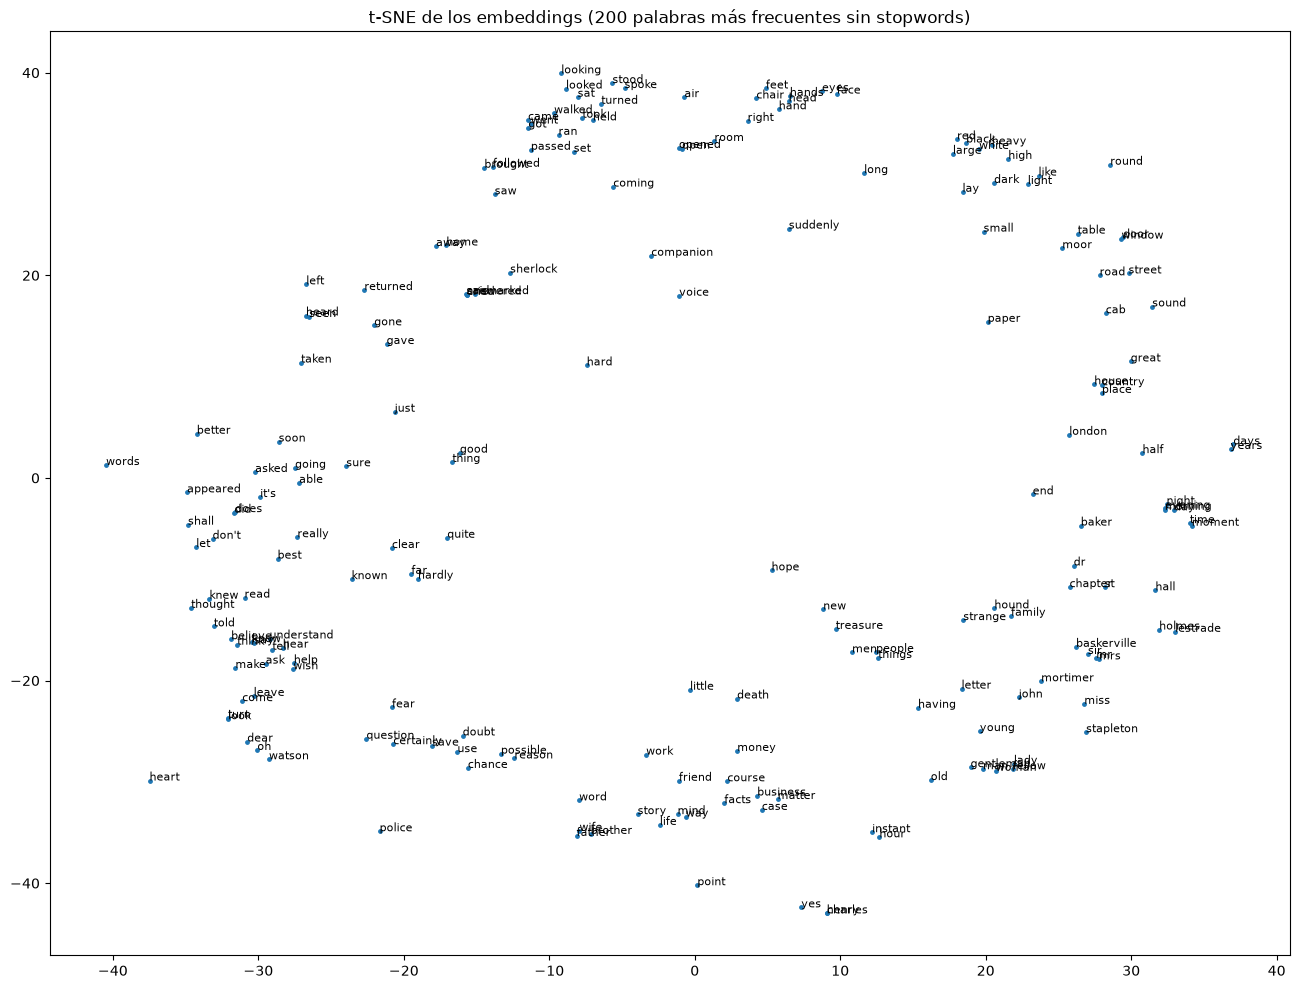

In [28]:
# Versión estática del gráfico 2D (se ve también fuera de Jupyter, por ejemplo en GitHub)
plt.figure(figsize=(16, 12))
plt.scatter(vecs[indices, 0], vecs[indices, 1], s=6)
for i in indices:
    plt.annotate(labels[i], (vecs[i, 0], vecs[i, 1]), fontsize=8)
plt.title(f"t-SNE de los embeddings ({MAX_WORDS} palabras más frecuentes sin stopwords)")
plt.show()

In [29]:
# Grupos encontrados en el gráfico: verificamos que también son cercanos en el espacio original (100D)
GRUPOS_TSNE = {
    "verbos de acción en pasado": ["went", "came", "walked", "stood", "sat", "ran", "turned", "looked"],
    "verbos de habla": ["said", "answered", "cried", "remarked", "asked"],
    "tiempo": ["night", "evening", "morning", "hour", "days", "years"],
    "partes del cuerpo": ["face", "eyes", "hands", "feet", "head"],
    "colores y tamaños": ["black", "white", "red", "small", "large", "dark"],
    "personas": ["man", "woman", "lady", "gentleman", "father", "brother", "wife"],
}

def similaridad_media(palabras):
    return np.mean([w2v_model.wv.similarity(a, b) for i, a in enumerate(palabras) for b in palabras[i + 1:]])

# Línea base: similaridad media entre pares al azar de las palabras graficadas
rng = np.random.default_rng(0)
pares_azar = rng.choice(labels[indices], size=(500, 2))
print(f"Línea base (pares al azar): {np.mean([w2v_model.wv.similarity(a, b) for a, b in pares_azar]):.2f}\n")
for nombre, palabras in GRUPOS_TSNE.items():
    print(f"{nombre:28s} similaridad media {similaridad_media(palabras):.2f}  {palabras}")

Línea base (pares al azar): 0.06

verbos de acción en pasado   similaridad media 0.50  ['went', 'came', 'walked', 'stood', 'sat', 'ran', 'turned', 'looked']
verbos de habla              similaridad media 0.64  ['said', 'answered', 'cried', 'remarked', 'asked']
tiempo                       similaridad media 0.37  ['night', 'evening', 'morning', 'hour', 'days', 'years']
partes del cuerpo            similaridad media 0.50  ['face', 'eyes', 'hands', 'feet', 'head']
colores y tamaños            similaridad media 0.49  ['black', 'white', 'red', 'small', 'large', 'dark']
personas                     similaridad media 0.38  ['man', 'woman', 'lady', 'gentleman', 'father', 'brother', 'wife']


**Interpretación de los grupos.**

Grupos que se observan en el gráfico t-SNE. Su similaridad media en el espacio original (100D) está muy por encima de la línea base de pares al azar (0.06):

| Grupo | Ejemplos | Similaridad media | Por qué se agrupan |
|---|---|---|---|
| Verbos de habla | said, answered, cried, remarked, asked | 0.64 | Introducen diálogos: siempre aparecen en el mismo patrón (`"...," said Holmes`). En el gráfico quedan pegados a `sherlock`, su sujeto más habitual. |
| Verbos de acción en pasado | went, came, walked, stood, sat, ran, turned, looked | 0.50 | Narración en pasado de movimientos ("he walked to the door"). |
| Partes del cuerpo | face, eyes, hands, feet, head | 0.50 | Descripciones físicas: "his face", "her eyes". En el gráfico aparecen junto a `chair`. |
| Colores y tamaños | black, white, red, small, large, dark | 0.49 | Adjetivos que modifican a los mismos sustantivos. |
| Personas | man, woman, lady, gentleman, father, brother, wife | 0.38 | En el gráfico son **dos subgrupos**: personas genéricas (`man, woman, lady, gentleman`) y parentesco (`father, brother, wife`). |
| Tiempo | night, evening, morning, hour, days, years | 0.37 | También se divide: partes del día (`morning, evening, night, time, moment`), duraciones largas (`days, years`) y cortas (`hour, instant`). |

Otras zonas del gráfico:
- Lugares físicos: `table, window, door, moor, road, street, cab, house`.
- Verbos mentales: `believe, think, understand, hear, wish, ask`.
- Nombres propios y títulos: `holmes, lestrade, mortimer, baskerville, stapleton, mrs, sir, dr`.

Los grupos de menor similaridad (personas, tiempo) son justamente los que t-SNE separa en subgrupos. Esto confirma que el gráfico refleja la estructura del espacio original. Como se vio en clase, t-SNE es estocástico y sirve solo como herramienta exploratoria: la distancia *entre* grupos no tiene significado, y la disposición exacta cambia si cambian los vectores.

In [30]:
# También se pueden guardar los vectores y labels como tsv para graficar en
# http://projector.tensorflow.org/


vectors = np.asarray(w2v_model.wv.vectors)
labels = list(w2v_model.wv.index_to_key)

np.savetxt("vectors.tsv", vectors, delimiter="\t")

with open("labels.tsv", "w") as fp:
    for item in labels:
        fp.write("%s\n" % item)

### 6 - Conclusiones

1. **Corpus.** Cuatro novelas de Holmes (~250 mil tokens, 3.830 palabras en el vocabulario con `min_count=5`) alcanzan para obtener embeddings con estructura interpretable. El ejemplo de clase (445 palabras) era insuficiente.
2. **Qué captura Word2Vec.** Agrupa palabras **intercambiables** en el mismo contexto: verbos de habla, partes del cuerpo, personajes que cumplen el mismo rol. En el Desafío 1, la co-ocurrencia por documento capturaba **tema** (`car → dealer`). La ventana de contexto produce una similaridad más gramatical y funcional.
3. **Skip-gram frente a CBOW.** La clase indica que skip-gram suele preferirse con corpus chicos por su precisión en palabras raras. En nuestra evaluación, con palabras frecuentes y analogías, ganó CBOW (10/12 contra 5/12). Skip-gram devolvió palabras que aparecen junto a la consulta, y CBOW palabras que la reemplazan. La elección depende de qué palabras y qué tipo de similitud interesa.
4. **Otros hiperparámetros.**
   - `negative=20`: alto, como se recomienda para corpus pequeños.
   - 300 dimensiones empeoraron el modelo por falta de datos.
   - La ventana tuvo un efecto menor.
5. **Los embeddings reflejan el uso en el corpus, no el conocimiento del mundo.** `watson` se parece a fórmulas de tratamiento porque es el narrador, y `fear` a verbos mentales porque se usa como "I fear that...".
6. **Antónimos y "menos similares".** Los antónimos quedan cerca porque comparten contextos, y las palabras "menos similares" no tienen relación semántica interpretable.
7. **Analogías.** Las relaciones gramaticales frecuentes (género, plural, pasado) funcionan; las semánticas y de dominio son inestables con un corpus chico.
8. **Limitaciones y próximos pasos:**
   - El corpus es chico, y hay palabras fuera de vocabulario (`hate` aparece solo 2 veces).
   - Cada palabra tiene un único vector, sin distinguir sentidos.
   - Con varios hilos el entrenamiento no es determinístico (`REPRODUCIBLE = True` lo resuelve a costa de velocidad).
   - Embeddings preentrenados en miles de millones de tokens (GloVe), o FastText (que usa n-gramas de caracteres y puede representar palabras no vistas), mejorarían las analogías semánticas y la cobertura del vocabulario.

### Consigna del desafío 2

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros)**

Recuerden que su notebook de entrega debe poder correrse de inicio a fin sin la aparición de errores.

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)